In [ ]:
!pip install praat-parselmouth
!pip install matplotlib
!pip install numpy
!pip install IPython
!pip install praat-textgrids

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.7/10.7 MB 87.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 50.4 MB/s eta 0:00:00


In [ ]:
import parselmouth
import matplotlib.pyplot as plt
#from parselmouth.praat import call

import IPython.display as ipd
from IPython.display import Audio
import numpy as np

import textgrids


In [ ]:
son = 'logatomes.wav'
grille = 'logatomes.TextGrid'

sound = parselmouth.Sound(son)

#sound = call("Read from file",son)
segmentation = textgrids.TextGrid(grille)
diphones = segmentation['phonemes']
channel = sound.values[0]

In [ ]:
def audio_player(audio_file):
    return ipd.display(Audio(audio_file))

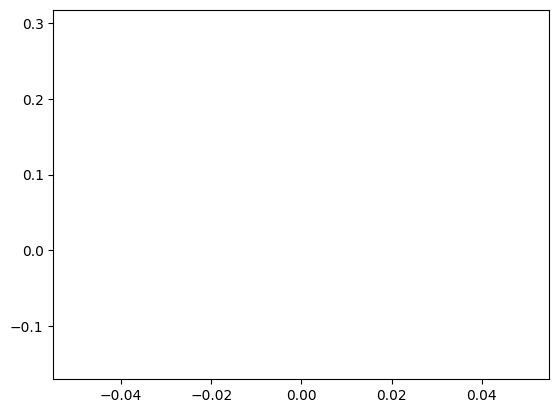

In [ ]:

debut1 = sound.extract_part(111,112.5,parselmouth.WindowShape.RECTANGULAR, 1, False)
debut2 = sound.extract_part(111,112.5,parselmouth.WindowShape.RECTANGULAR, 1, False)


son_total = sound.concatenate([debut1,debut2])

#plt.plot(son_total.xs(),son_total.values.T)
plt.plot(son_total.values)

ipd.display(Audio(son_total.values, rate=son_total.sampling_frequency))


In [ ]:
chaine_sampa = "sEtynafER"

#extraits_diphones = {}
synthese = []

for j in range(len(chaine_sampa)-1):
  diphone = chaine_sampa[j:j+2]
  phoneme1 = diphone[0]
  phoneme2 = diphone[1]
  #print(phoneme1)


  for a in range(len(diphones)-1):

      if diphones[a].text == phoneme1 and diphones[a+1].text == phoneme2:
          milieu1 = (diphones[a].xmin + diphones[a].xmax)/2
          milieu2 = (diphones[a+1].xmin + diphones[a+1].xmax)/2

          start_idx = int(milieu1 * sound.sampling_frequency)
          end_idx = int(milieu2 * sound.sampling_frequency)


          for b in range(start_idx,end_idx):
              if channel[b] <= 0 and channel[b+1] > 0:
                  clean_start = b/sound.sampling_frequency
                  break

          for b in reversed(range(start_idx,end_idx)):
              if channel[b] <= 0 and channel[b+1] > 0:
                  clean_end = b/sound.sampling_frequency
                  break

          extraction = sound.extract_part(from_time=clean_start,to_time=clean_end,preserve_times=False)
          #extraits_diphones[diphone] = extraction
          #print(f"'{diphone}' {extraction}")
          synthese.append(extraction.values)



[array([[-0.00064087,  0.00250244,  0.00073242, ..., -0.00942993,
        -0.006073  , -0.00366211]])]
[array([[-0.00064087,  0.00250244,  0.00073242, ..., -0.00942993,
        -0.006073  , -0.00366211]]), array([[-0.00134277,  0.00219727,  0.00576782, ..., -0.00036621,
        -0.00021362, -0.00021362]])]
[array([[-0.00064087,  0.00250244,  0.00073242, ..., -0.00942993,
        -0.006073  , -0.00366211]]), array([[-0.00134277,  0.00219727,  0.00576782, ..., -0.00036621,
        -0.00021362, -0.00021362]]), array([[-0.00018311,  0.00015259,  0.00024414, ..., -0.00790405,
        -0.00582886, -0.00375366]])]
[array([[-0.00064087,  0.00250244,  0.00073242, ..., -0.00942993,
        -0.006073  , -0.00366211]]), array([[-0.00134277,  0.00219727,  0.00576782, ..., -0.00036621,
        -0.00021362, -0.00021362]]), array([[-0.00018311,  0.00015259,  0.00024414, ..., -0.00790405,
        -0.00582886, -0.00375366]]), array([[-0.00326538,  0.00140381,  0.00668335, ..., -0.00125122,
        -0.00

In [ ]:

# Concaténer tous les segments le long du temps
concatenated = np.hstack(synthese)

# Créer un nouveau Sound
new_sound = parselmouth.Sound(values=concatenated,
                              sampling_frequency=sound.sampling_frequency)

# Jouer le son
ipd.display(Audio(new_sound.values, rate=new_sound.sampling_frequency))


script final avec dico et fonctions


In [ ]:
parler de "_s"

In [ ]:



def zero_crossing_bounds(channel, start_idx, end_idx, sr):
    """Trouve les bornes propres par passage à zéro."""
    clean_start = start_idx / sr
    clean_end = end_idx / sr

    for i in range(start_idx, end_idx - 1):
        if channel[i] <= 0 < channel[i + 1]:
            clean_start = i / sr
            break

    for i in range(end_idx - 1, start_idx, -1):
        if channel[i] <= 0 < channel[i + 1]:
            clean_end = i / sr
            break

    return clean_start, clean_end


def extraire_diphone(sound, interval1, interval2):
    """Extrait un diphone entre deux intervalles."""
    sr = sound.sampling_frequency
    channel = sound.values[0]

    milieu1 = (interval1.xmin + interval1.xmax) / 2
    milieu2 = (interval2.xmin + interval2.xmax) / 2

    start_idx = int(milieu1 * sr)
    end_idx = int(milieu2 * sr)

    clean_start, clean_end = zero_crossing_bounds(channel, start_idx, end_idx, sr)

    return sound.extract_part(
        from_time=clean_start,
        to_time=clean_end,
        preserve_times=False
    )


def construire_diphones(sound, diphone_tier, chaine_sampa):
    """Construit un dict diphone -> extrait audio."""
    extraits = {}

    paires_cibles = [chaine_sampa[i:i+2] for i in range(len(chaine_sampa) - 1)]

    for i in range(len(diphone_tier) - 1):
        interval1 = diphone_tier[i]
        interval2 = diphone_tier[i + 1]

        diphone = interval1.text + interval2.text

        if diphone in paires_cibles:
            extrait = extraire_diphone(sound, interval1, interval2)
            extraits[diphone] = extrait
            print(diphone, "extrait")

    return extraits


# ---------- script principal ----------

son = "logatomes.wav"
grille = "logatomes.TextGrid"
chaine_sampa = "sEtynafER"

sound = parselmouth.Sound(son)
segmentation = textgrids.TextGrid(grille)
diphones = segmentation["phonemes"]

extraits_diphones = construire_diphones(sound, diphones, chaine_sampa)


# ---------- concaténation de la phrase ----------

segments = []

for i in range(len(chaine_sampa) - 1):
    diphone = chaine_sampa[i:i+2]
    segments.append(extraits_diphones[diphone].values[0])
    signal = np.concatenate(segments)

phrase = parselmouth.Sound(
    signal,
    sampling_frequency=sound.sampling_frequency
)


ipd.display(Audio(signal, rate=int(sound.sampling_frequency)))


In [ ]:
# modification prosodique par PSOLA

from parselmouth.praat import call

sound = parselmouth.Sound('sEtynafER.wav')


manipulation = call(sound, "To Manipulation", 0.01, 75, 600)
pitch_tier = call(manipulation, "Extract pitch tier")
call(pitch_tier, "Multiply frequencies", sound.xmin, sound.xmax, 1.2)

call([manipulation, pitch_tier], "Replace pitch tier")

resynth = call(manipulation, "Get resynthesis (overlap-add)")


duration_tier = call(manipulation, "Extract duration tier")
call(duration_tier, "Add point", 0.5, 1.5)
call([manipulation, duration_tier], "Replace duration tier")

resynth = call(manipulation, "Get resynthesis (overlap-add)")

resynth.save("toto.wav","WAV")

ipd.display(Audio(resynth.values, rate=resynth.sampling_frequency))

####################################

t0 = new_sound.xmin
t1 = new_sound.xmax
dur = t1 - t0

# valeurs en Hz (à adapter selon voix)
call(pitch_tier, "Add point", t0 + 0.00 * dur, 110)   # début
call(pitch_tier, "Add point", t0 + 0.40 * dur, 140)   # montée
call(pitch_tier, "Add point", t0 + 0.75 * dur, 125)   # stabilisation
call(pitch_tier, "Add point", t0 + 0.95 * dur, 95)    # chute finale



